# VCT Meta Lens — Exploration du dataset VCT 2025

Exploration des données nettoyées (`data/processed/`) avant construction du dashboard Power BI.

**Objectifs de ce notebook :**
1. Valider le pipeline de nettoyage (`src/clean.py`)
2. Repérer les premières tendances méta qui guideront les pages du dashboard
3. Documenter les pièges du dataset (agrégats, NaN structurels)

> Les visuels finaux seront faits dans Power BI à partir de `data/model/` — ce notebook sert uniquement d'exploration.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Permet d'importer src/ depuis notebooks/
sys.path.append(str(Path.cwd().parent))
from src.config import PROCESSED_DIR, TOURNAMENT_META

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (11, 4.5)

## 1. Pick rates des agents

⚠️ **Piège n°1 du dataset** : `agents_pick_rates` mélange lignes de détail et lignes d'agrégats
(`All Maps`, `All Stages`, `All Match Types`). Les flags `is_*_agg` posés par `clean.py`
permettent de les écarter explicitement.

In [2]:
picks = pd.read_parquet(PROCESSED_DIR / "agents_pick_rates.parquet")
print(f"{len(picks)} lignes au total, dont :")
print(f"  - {picks['is_map_agg'].sum()} lignes 'All Maps'")
print(f"  - {picks['is_stage_agg'].sum()} lignes 'All Stages'")
print(f"  - {picks['is_match_type_agg'].sum()} lignes 'All Match Types'")

detail = picks[~picks.is_map_agg & ~picks.is_stage_agg & ~picks.is_match_type_agg]
print(f"\n{len(detail)} lignes de détail conservées pour l'analyse")
detail.head()

30294 lignes au total, dont :
  - 5454 lignes 'All Maps'
  - 3240 lignes 'All Stages'
  - 3240 lignes 'All Match Types'

22005 lignes de détail conservées pour l'analyse


,tournament,stage,match_type,map,agent,pick_rate,is_map_agg,is_stage_agg,is_match_type_agg
27,Valorant Champions 2025,Playoffs,Upper Quarterfinals,Lotus,omen,100,False,False,False
28,Valorant Champions 2025,Playoffs,Upper Quarterfinals,Lotus,yoru,50,False,False,False
29,Valorant Champions 2025,Playoffs,Upper Quarterfinals,Lotus,viper,67,False,False,False
30,Valorant Champions 2025,Playoffs,Upper Quarterfinals,Lotus,sova,0,False,False,False
31,Valorant Champions 2025,Playoffs,Upper Quarterfinals,Lotus,vyse,50,False,False,False


### Évolution du méta sur la saison 2025

L'angle central du dashboard : comment le pick rate des agents évolue de Kickoff à Champions.
L'ordre chronologique des tournois n'existe pas dans les données — il vient de `src/config.py`.

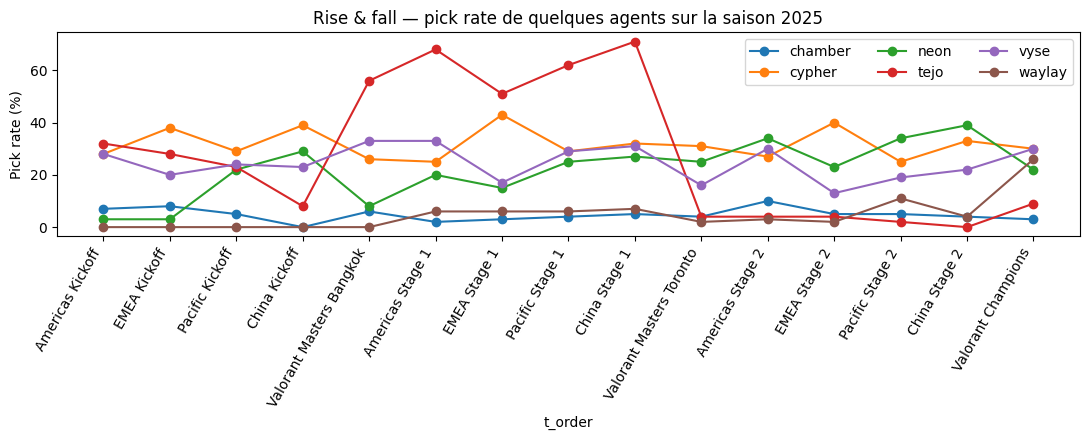

In [3]:
order = {t: m["order"] for t, m in TOURNAMENT_META.items()}

# Pick rate moyen par agent et par tournoi (sur les lignes "All Maps" au niveau
# stage agrégé : c'est l'agrégat le plus comparable d'un tournoi à l'autre)
season = picks[picks.is_map_agg & picks.is_stage_agg & picks.is_match_type_agg].copy()
season["t_order"] = season["tournament"].map(order)

focus_agents = ["tejo", "waylay", "vyse", "chamber", "cypher", "neon"]
pivot = (season[season.agent.isin(focus_agents)]
         .pivot_table(index="t_order", columns="agent", values="pick_rate"))

ax = pivot.plot(marker="o")
ax.set_xticks(sorted(order.values()))
ax.set_xticklabels([t.replace("VCT 2025: ", "").replace(" 2025", "")
                    for t in sorted(order, key=order.get)], rotation=60, ha="right")
ax.set_ylabel("Pick rate (%)")
ax.set_title("Rise & fall — pick rate de quelques agents sur la saison 2025")
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

## 2. Équilibre attaque / défense par map

⚠️ Même piège d'agrégats dans `maps_stats`. On garde le niveau tournoi (`All Stages`)
mais map détaillée.

In [4]:
maps = pd.read_parquet(PROCESSED_DIR / "maps_stats.parquet")
mdetail = maps[~maps.is_map_agg & maps.is_stage_agg & maps.is_match_type_agg]

balance = (mdetail.groupby("map")[["attacker_side_win_percentage",
                                    "defender_side_win_percentage"]]
           .mean().round(1).sort_values("attacker_side_win_percentage"))
balance

,attacker_side_win_percentage,defender_side_win_percentage
map,,
Ascent,46.2,53.8
Corrode,48.8,51.2
Sunset,48.8,51.2
Split,49.1,50.9
Bind,49.2,50.8
Lotus,50.5,49.5
Fracture,51.3,48.7
Pearl,51.8,48.2
Haven,52.0,48.0


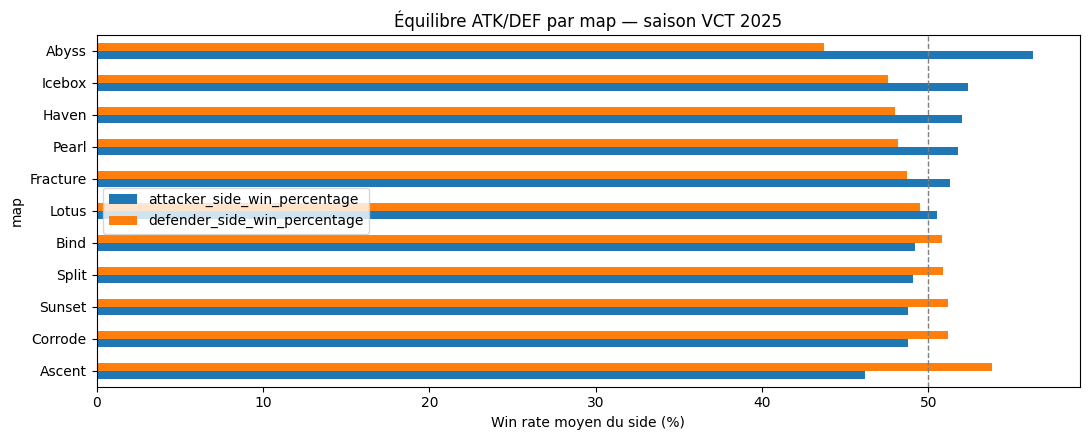

In [5]:
ax = balance.plot(kind="barh")
ax.axvline(50, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Win rate moyen du side (%)")
ax.set_title("Équilibre ATK/DEF par map — saison VCT 2025")
plt.tight_layout()
plt.show()

## 3. Stats joueurs (overview)

⚠️ **Piège n°2** : chaque joueur a jusqu'à 3 lignes par carte (`side` = both / attack / defend),
et les stats par side sont partiellement vides chez VLR. Pour toute analyse standard :
filtrer `side == "both"`. C'est ce que fait `fact_player_map` dans le modèle.

In [6]:
ov = pd.read_parquet(PROCESSED_DIR / "overview.parquet")
print(ov.groupby("side")["rating"].apply(lambda s: f"{s.isna().mean():.0%} de NaN"))

both = ov[ov.side == "both"]
top = (both.groupby("player")
       .agg(maps=("map", "count"), rating=("rating", "mean"), acs=("average_combat_score", "mean"))
       .query("maps >= 30").sort_values("rating", ascending=False).head(10).round(2))
top

side
attack    8% de NaN
both      8% de NaN
defend    8% de NaN
Name: rating, dtype: str


,maps,rating,acs
player,,,
slowly,51,1.23,236.69
Cryocells,64,1.18,229.84
aspas,98,1.16,238.43
trent,138,1.15,204.82
vo0kashu,82,1.15,220.57
keiko,127,1.15,221.68
SUYGETSU,57,1.14,202.43
leaf,114,1.14,226.79
Ruxic,68,1.13,228.04


## 4. Conversion économique des équipes

`eco_stats` : rounds initiés vs gagnés par catégorie d'achat. Le taux de conversion des
ecos/semi-ecos est un bon différenciateur d'équipes pour la page Équipes du dashboard.

In [7]:
eco = pd.read_parquet(PROCESSED_DIR / "eco_stats.parquet")
conv = (eco.groupby(["team", "type"])[["initiated", "won"]].sum()
        .assign(win_rate=lambda d: (d.won / d.initiated * 100).round(1))
        .reset_index())

pistols = (conv[conv.type == "Pistol Won"].query("initiated >= 80")
           .sort_values("win_rate", ascending=False).head(10))
pistols[["team", "initiated", "won", "win_rate"]]

,team,initiated,won,win_rate


## Conclusions pour le dashboard

1. **Le filtrage des agrégats est non négociable** — tout `groupby` naïf sur les CSV bruts double-compte.
2. La dimension tournoi (ordre + région, dans `dim_tournament`) rend l'axe temporel exploitable : c'est elle qui porte la page **Méta agents**.
3. `side == "both"` est la granularité de référence pour les stats joueurs.
4. Les tables de `data/model/` sont prêtes à être importées dans Power BI (CSV UTF-8 BOM).

Prochaine étape : modèle de données Power BI (relations sur `tournament`, `agent`, `map`, `team`, `player`) puis page Méta agents.